# Environmental colonization pressure and prior antibiotic exposure as risk factors for hospital-acquired infection

A matched case-control analysis of the PhysioNet *Predictors of Hospital-Onset Infection* dataset.

Manuscript title: *Comparative Analysis of Environmental Colonization Pressure and Prior
Antibiotic Exposure as Risk Factors for Hospital-Acquired Infections: A Matched Case-Control
Study* (Opiyo and Nyakairu, submitted to the Journal of Hospital Infection).

This is revision 1. Analyses added or altered after peer review are tagged `[REV-n]`, where
`n` is the reviewer comment number, and are listed in the revision log below. The original
analyses are retained and still run, so the revision-0 estimates remain reproducible alongside
the new ones.

## Aim

To compare the independent associations of environmental colonization pressure (CP) and prior
antibiotic exposure with hospital-acquired infection (HAI) among adult hospitalised patients,
using two complementary matched case-control cohorts.

## Research questions

The primary question is which of the two exposures, environmental colonization pressure or
prior antibiotic exposure, shows the stronger association with HAI among hospitalised adults.
Four secondary questions follow from it: which colonization-pressure measures are associated
with HAI; which antibiotic classes are associated with HAI; whether patient characteristics
such as age, sex, surgery and comorbidity modify these associations; and whether the
associations are consistent across pathogens.

## Objectives

1. Describe the demographic and clinical characteristics of cases and controls.
2. Estimate the association between colonization pressure and HAI in the environmental cohort.
3. Estimate the association between prior antibiotic exposure and HAI in the patient cohort.
4. Identify independent predictors after adjustment for confounders.
5. Compare the magnitude of the environmental and antibiotic associations on a common scale.

## Design

The released dataset contains two matched cohorts. In the environmental cohort, controls are
matched to cases on antibiotic exposure, age, sex, surgery and length of stay, which leaves the
ward environment as the exposure that still varies within a matched set. In the patient cohort,
controls are matched on ward, admission month and year, and length of stay, which holds the
environment approximately fixed and leaves the patient's own antibiotic history free to vary.
Because the data are individually matched in variable ratios, estimation throughout uses
conditional logistic regression stratified on the matched set.

---

## Revision log

| Reviewer comment | Issue | Revision | Section |
|---|---|---|---|
| Major 1: length-of-stay imbalance (SMD 0.586 and 0.605) is a time-dependent bias that conditional regression does not remove | Table I reported `duration`, total room occupancy. The variable matching was performed on, `matching_duration`, was not reported. No duration-adjusted or landmark analysis was present. | Both duration variables reported with SMDs; duration-adjusted models added; landmark analysis added requiring every member of a matched set to have remained at least L days | 4, 7b, 7c |
| Major 2: the inverse antibiotic associations and the claim that one pathway was stronger were stated too strongly | The findings cell asserted which pathway was stronger on the basis of a cross-scale comparison, in causal language | Primary comparison refitted on a common scale; findings text restated as association, with the candidate bias mechanisms named | 7d, 12 |
| Major 3: the outcome is culture or surveillance positivity, not clinical infection | The outcome was not defined | Outcome-definition section added, documenting that specimen type is not present in the released data | 2b |
| Major 4: a per-SD against per-course comparison is not interpretable | `STANDARDIZE_ABX` was defined in the configuration but never referenced, so the per-SD antibiotic model was never fitted | Implemented; both exposures now compared per 1 SD; Figure 5 redrawn on the common scale | 7d, 11 |
| Major 5: 20,060/47,283 in Methods against 20,056/47,277 in the Abstract, with 10 records unexplained | Exclusion of non-informative strata happened implicitly inside the estimator | Exclusion-flow table added, accounting for every record from the released file to the modelled sample | 2a |
| Minor: no multiple-testing correction across the 36 interactions | Only nominal p values were reported | Bonferroni and Benjamini-Hochberg columns added; interactions labelled exploratory | 9 |
| Minor: table numbering did not match the manuscript | Notebook used Arabic numerals, manuscript Roman | Notebook labels now follow the manuscript (Tables I to XII); new tables are XIII to XVI | throughout |
| Minor: share the analysis code | No version capture or archiving block | Software-version capture and a code-availability block added | 14 |

Runtime on the full data is approximately 20 to 25 minutes, of which the patient-cohort fits
account for most.

---

## 1. Environment and configuration

Tunable options are collected here. `DATA_PATH` is resolved against a short list of common
locations. Two switches matter analytically:

`STANDARDIZE_CP` expresses colonization-pressure odds ratios per 1 SD increase. Raw CP units
have no clinical interpretation, and standardisation is what makes the CP and antibiotic
estimates comparable for the primary question.

`FAST_MODE` subsamples whole matched sets so the notebook completes in one to two minutes as a
check that it runs. It must be `False` for the reported analysis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, warnings, itertools, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.discrete.conditional_models import ConditionalLogit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrix

warnings.filterwarnings("ignore")           # keep the notebook output readable
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# ------------------------------------------------------------------ CONFIG
DATA_PATH_CANDIDATES = [
    "/content/drive/MyDrive/Hospital Onset Infection/HO_infxn_analysis.csv",  # Google Colab
    "HO_infxn_analysis.csv",                                          # local working dir
    "/mnt/data/HO_infxn_analysis.csv",
]
STANDARDIZE_CP  = True     # CP odds ratios per 1 SD
STANDARDIZE_ABX = True     # [REV-4] antibiotic odds ratios per 1 SD, used in section 7d.
                           # In revision 0 this flag was defined but never referenced, so the
                           # per-SD antibiotic model was never fitted and the cross-cohort
                           # comparison ran on non-comparable units.
LANDMARK_DAYS   = [3, 5, 7]  # [REV-1] landmark thresholds (days) for the time-bias analysis
FAST_MODE       = False    # True = subsample matched sets for a quick run-through
FAST_SETS_PER_RUN = 60     # matched sets kept per pathogen when FAST_MODE
RANDOM_SEED     = 42
OUTPUT_DIR      = "hai_outputs"   # tables + figures are written here

os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(RANDOM_SEED)

DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "HO_infxn_analysis.csv not found. Edit DATA_PATH_CANDIDATES to point at the file.")
print("Using data file:", DATA_PATH)
print("FAST_MODE =", FAST_MODE, "| STANDARDIZE_CP =", STANDARDIZE_CP)


Using data file: /content/drive/MyDrive/Hospital Onset Infection/HO_infxn_analysis.csv
FAST_MODE = False | STANDARDIZE_CP = True


## 2. Loading the data and detecting its structure

The published file bundles both analyses, distinguished by the `analysis` column. Variable
groups are detected by pattern rather than hard-coded, so the code tolerates renaming:
colonization pressure is any column ending `_cp`; antibiotic classes are columns ending `_0_60`
other than the `any_abx_0_60` flag; individual Elixhauser comorbidities are columns beginning
`elix_` other than `elix_index_mortality`.

The matched-set identifier used as the stratum for conditional logistic regression is
`analysis | run | group_index`. Each stratum is verified to contain one case and up to three
controls, as the design specifies.

In [ ]:
# ---- load ----------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

# ---- detect variable groups by pattern -----------------------------------
CP_COLS   = sorted([c for c in df.columns if c.endswith("_cp")])
ABX_COLS  = sorted([c for c in df.columns if c.endswith("_0_60") and c != "any_abx_0_60"])
ELIX_COLS = sorted([c for c in df.columns if c.startswith("elix_") and c != "elix_index_mortality"])
print(f"Detected {len(CP_COLS)} CP vars, {len(ABX_COLS)} antibiotic classes, {len(ELIX_COLS)} comorbidities.")

# ---- derived variables ----------------------------------------------------
# age is stored as text and contains a '>90' category -> coerce to numeric (>=90 -> 90)
df["age_num"] = pd.to_numeric(df["age"].astype(str).str.replace(">", "", regex=False), errors="coerce")
# sex -> male indicator; the 2 'Other' rows become NaN (dropped only where sex is used)
df["is_male"] = np.where(df["sex"] == "Male", 1, np.where(df["sex"] == "Female", 0, np.nan))
# the matched-set / stratum identifier used by every conditional model
df["stratum"] = df["analysis"].astype(str) + "|" + df["run"].astype(str) + "|" + df["group_index"].astype(str)

# ---- verify the matched-set structure ------------------------------------
chk = df.groupby("stratum")["group_binary"].agg(cases="sum", size="count")
print("\nMatched-set check (stratum = analysis|run|group_index):")
print(f"  strata total                : {len(chk):,}")
print(f"  strata with exactly 1 case  : {(chk['cases']==1).mean():.4f}")
print(f"  set-size range (case+ctrls) : {chk['size'].min()}-{chk['size'].max()} (median {int(chk['size'].median())})")

# [REV-5] record the pre-exclusion counts so every dropped record can be accounted for
FLOW = {}
for coh in ["environmental", "patient"]:
    s = df[df["analysis"] == coh]
    FLOW[(coh, "raw")] = (int((s.group_binary == 1).sum()), int((s.group_binary == 0).sum()))

# Conditional logit only uses strata that contain BOTH a case and >=1 control:
# a stratum with no case, or no control, contributes nothing to the conditional
# likelihood because there is no within-stratum outcome variation to condition on.
chk_all = chk.copy()
valid = chk.index[(chk["cases"] == 1) & (chk["size"] >= 2)]
DROPPED_STRATA = chk_all.loc[~chk_all.index.isin(valid)].copy()   # [REV-5] keep for audit
df = df[df["stratum"].isin(valid)].copy()
for coh in ["environmental", "patient"]:
    s = df[df["analysis"] == coh]
    FLOW[(coh, "informative")] = (int((s.group_binary == 1).sum()), int((s.group_binary == 0).sum()))
print(f"  informative strata retained : {len(valid):,} "
      f"({df.shape[0]:,} rows kept for analysis)")


Raw shape: (120279, 78)
Detected 9 CP vars, 14 antibiotic classes, 38 comorbidities.

Matched-set check (stratum = analysis|run|group_index):
  strata total                : 37,959
  strata with exactly 1 case  : 0.9999
  set-size range (case+ctrls) : 1-4 (median 3)
  informative strata retained : 37,951 (120,269 rows kept for analysis)


### 2a. Exclusion flow [REV-5]

Reviewer comment 5 noted that the patient cohort is reported as 20,060/47,283 in the Methods
and as 20,056/47,277 in the Abstract and Results, and asked for the 10 excluded records to be
explained.

The discrepancy arises because four distinct sample sizes exist in this analysis and two of
them were previously used interchangeably:

1. As released: every row in the file.
2. After dropping non-informative matched sets. A stratum containing only cases, or only
   controls, contributes nothing to the conditional likelihood and is removed by the estimator.
   This accounts for the 10 patient-cohort records.
3. After complete-case restriction on the model covariates. Two further records are lost
   because sex is recorded as `Other`, leaving the male indicator undefined.
4. After the cascade that step 3 causes. Removing a case can leave its matched set without any
   case, which makes the set non-informative and removes its remaining controls as well.

The cell below prints the full flow and identifies every excluded stratum, so the accounting is
explicit and reproducible.

In [ ]:
# [REV-5] ---- exclusion flow: every record accounted for ---------------------
flow_rows = []
for coh in ["environmental", "patient"]:
    raw_c, raw_n = FLOW[(coh, "raw")]
    inf_c, inf_n = FLOW[(coh, "informative")]
    # complete-case on the covariates every model uses
    s = df[df["analysis"] == coh]
    need = ["age_num", "is_male", "any_surgery", "elix_index_mortality"]
    ok = s[need].apply(pd.to_numeric, errors="coerce").notna().all(axis=1)
    mod_c, mod_n = int((s[ok].group_binary == 1).sum()), int((s[ok].group_binary == 0).sum())
    flow_rows += [
        dict(Cohort=coh, Stage="1. As released in the dataset",
             Cases=raw_c, Controls=raw_n, Total=raw_c + raw_n, Excluded=""),
        dict(Cohort=coh, Stage="2. After removing non-informative matched sets",
             Cases=inf_c, Controls=inf_n, Total=inf_c + inf_n,
             Excluded=f"{(raw_c-inf_c)+(raw_n-inf_n)} records "
                      f"({raw_c-inf_c} cases, {raw_n-inf_n} controls)"),
        dict(Cohort=coh, Stage="3. Complete-case on model covariates",
             Cases=mod_c, Controls=mod_n, Total=mod_c + mod_n,
             Excluded=f"{(inf_c-mod_c)+(inf_n-mod_n)} records "
                      f"({inf_c-mod_c} case, {inf_n-mod_n} control; sex = 'Other')"),
    ]
    # [REV-5] CASCADE: removing a case can leave its matched set with no case at
    # all. Such a set is no longer informative and the estimator drops it, taking
    # its remaining controls with it. This step was missing from revision 1.
    cc = s[ok]
    c2 = cc.groupby("stratum")["group_binary"].agg(cases="sum", size="count")
    good = c2.index[(c2["cases"] >= 1) & (c2["size"] >= 2)]
    broken = c2.loc[~c2.index.isin(good)]
    eff = cc[cc["stratum"].isin(good)]
    eff_c, eff_n = int((eff.group_binary == 1).sum()), int((eff.group_binary == 0).sum())
    flow_rows.append(
        dict(Cohort=coh, Stage="4. Analysed, after cascade",
             Cases=eff_c, Controls=eff_n, Total=eff_c + eff_n,
             Excluded=(f"{int(broken['size'].sum())} records in {len(broken)} set(s) "
                       f"left with no case" if len(broken) else "0 records")))
flow_tbl = pd.DataFrame(flow_rows)
flow_tbl.to_csv(f"{OUTPUT_DIR}/tableXVI_exclusion_flow.csv", index=False)
print("=== TABLE XVI — Exclusion flow [REV-5] ===")
display(flow_tbl)

# which strata were dropped, and why
if len(DROPPED_STRATA):
    d = DROPPED_STRATA.copy()
    d["reason"] = np.where(d["cases"] == 0, "no case in set",
                   np.where(d["size"] < 2, "case with no matched control", "other"))
    d = d.reset_index()
    d["cohort"] = d["stratum"].str.split("|").str[0]
    print("\nNon-informative matched sets excluded, individually listed [REV-5]:")
    display(d[["stratum", "cohort", "cases", "size", "reason"]])
    print(f"\nTotal excluded: {len(d)} strata, {int(d['size'].sum())} records "
          f"({int(d['cases'].sum())} cases, {int((d['size']-d['cases']).sum())} controls)")
    d.to_csv(f"{OUTPUT_DIR}/diag_excluded_strata.csv", index=False)
print("\nStage-4 figures are the analysed sample: they are what the models fit on.")

=== TABLE XVI — Exclusion flow [REV-5] ===


,Cohort,Stage,Cases,Controls,Total,Excluded
0,environmental,1. As released in the dataset,17895,35041,52936,
1,environmental,2. After removing non-informative matched sets,17895,35041,52936,"0 records (0 cases, 0 controls)"
2,environmental,3. Complete-case on model covariates,17895,35041,52936,"0 records (0 case, 0 control; sex = 'Other')"
3,environmental,"4. Analysed, after cascade",17895,35041,52936,0 records
4,patient,1. As released in the dataset,20060,47283,67343,
5,patient,2. After removing non-informative matched sets,20056,47277,67333,"10 records (4 cases, 6 controls)"
6,patient,3. Complete-case on model covariates,20055,47276,67331,"2 records (1 case, 1 control; sex = 'Other')"
7,patient,"4. Analysed, after cascade",20055,47273,67328,3 records in 1 set(s) left with no case



Non-informative matched sets excluded, individually listed [REV-5]:


,stratum,cohort,cases,size,reason
0,patient|DR_P_aeruginosa|400,patient,1,1,case with no matched control
1,patient|DS_K_pneumoniae|906,patient,0,1,no case in set
2,patient|ESBL_E_cloacae|135,patient,1,1,case with no matched control
3,patient|ESBL_E_cloacae|196,patient,0,3,no case in set
4,patient|MRSA|631,patient,0,1,no case in set
5,patient|MSSA|1002,patient,1,1,case with no matched control
6,patient|MSSA|1031,patient,1,1,case with no matched control
7,patient|MSSA|1319,patient,0,1,no case in set



Total excluded: 8 strata, 10 records (4 cases, 6 controls)

Stage-4 figures are the analysed sample: they are what the models fit on.


### 2b. Outcome definition [REV-3]

Reviewer comment 3 noted that colonization pressure predicts culture or surveillance
positivity rather than infection, and asked for the distinction between clinical infection,
colonization and microbiological detection to be defined.

A case is a patient from whom the target organism was recovered from a clinical or surveillance
specimen, from any body site, during the observation window following ward entry.

This is microbiological detection rather
than adjudicated clinical infection: no clinical criteria were applied, so a patient who is
asymptomatically colonized and happens to be sampled meets the case definition. Second,
colonization and infection cannot be separated in these data, because the released file carries
no specimen type, no clinical variables and no infection adjudication; the cell below confirms
this against the column list. Third, detection depends on being
cultured, so patients sampled more often are more likely to become cases independently of their
true acquisition risk, which is also the mechanism underlying reviewer comments 1 and 2.

The primary publication for the source dataset uses the term nosocomial pathogen acquisition
rather than infection. The notebook below uses acquisition and detection language throughout.

In [ ]:
# [REV-3] ---- verify what the data can and cannot distinguish ---------------
print("Outcome variable:", "group_binary  (1 = case, 0 = matched control)")
print("Case definition : target organism recovered from a clinical OR surveillance specimen")
print("                  during the observation window after ward entry.\n")

# Does the released file let us separate clinical infection from colonisation?
wanted = {
    "specimen type (clinical vs surveillance)": ["specimen", "source", "sample", "culture_type"],
    "body site":                                ["site", "bodysite"],
    "symptoms / clinical signs":                ["symptom", "fever", "sign", "clinical"],
    "infection adjudication / NHSN criteria":   ["infection_flag", "adjudicat", "nhsn", "cdc_"],
    "treatment for infection":                  ["treat", "therapy"],
}
print("Can the outcome be refined to clinical infection with the released data?")
for label, pats in wanted.items():
    hits = [c for c in df.columns if any(p in c.lower() for p in pats)]
    print(f"   {label:42s} {'FOUND: ' + ', '.join(hits) if hits else 'NOT AVAILABLE'}")

print("\n=> No specimen-type, site, symptom or adjudication field exists in the released data.")
print("   The outcome therefore cannot be narrowed to clinically adjudicated infection.")
print("   The outcome is microbiologically confirmed acquisition and detection.")


# time_to_infxn is defined only for cases - relevant to comments 1 and 3
print(f"\ntime_to_infxn present for {int(df['time_to_infxn'].notna().sum()):,} rows "
      f"({int(df.loc[df.group_binary==1,'time_to_infxn'].notna().sum()):,} of "
      f"{int((df.group_binary==1).sum()):,} cases; "
      f"{int(df.loc[df.group_binary==0,'time_to_infxn'].notna().sum()):,} of "
      f"{int((df.group_binary==0).sum()):,} controls)")
print("   -> detection time exists only for cases, so it cannot be used as a covariate;")
print("      it is used instead to define the landmark analysis in section 7c.")

Outcome variable: group_binary  (1 = case, 0 = matched control)
Case definition : target organism recovered from a clinical OR surveillance specimen
                  during the observation window after ward entry.

Can the outcome be refined to clinical infection with the released data?
   specimen type (clinical vs surveillance)   NOT AVAILABLE
   body site                                  NOT AVAILABLE
   symptoms / clinical signs                  NOT AVAILABLE
   infection adjudication / NHSN criteria     NOT AVAILABLE
   treatment for infection                    NOT AVAILABLE

=> No specimen-type, site, symptom or adjudication field exists in the released data.
   The outcome therefore cannot be narrowed to clinically adjudicated infection.
   The outcome is microbiologically confirmed acquisition and detection.

time_to_infxn present for 37,951 rows (37,951 of 37,951 cases; 0 of 82,318 controls)
   -> detection time exists only for cases, so it cannot be used as a covariate;
   

## 3. Cohorts, variable lists and pathogen resistance labels

The two matched cohorts are separated here, and each pathogen `run` is labelled drug-resistant
or drug-susceptible for the pathogen-stratified sensitivity analyses and for the question of
whether associations are consistent across pathogens. The classification rule is printed so it
can be inspected and overridden.

In [ ]:
# ---- optional FAST_MODE subsampling (keeps WHOLE matched sets) ------------
def subsample_sets(frame, per_run=FAST_SETS_PER_RUN, seed=RANDOM_SEED):
    keep = []
    for (an, rn), g in frame.groupby(["analysis", "run"]):
        sids = g["stratum"].unique()
        rng = np.random.default_rng(seed)
        if len(sids) > per_run:
            sids = rng.choice(sids, per_run, replace=False)
        keep.extend(sids)
    return frame[frame["stratum"].isin(keep)].copy()

if FAST_MODE:
    df = subsample_sets(df)
    print(f"FAST_MODE ON -> subsampled to {df.shape[0]:,} rows")

# [REV-5] Restrict to the ANALYSED sample BEFORE splitting, so that Table I/II,
# the balance plot, every model and the study-flow figure all describe exactly the
# same patients. Two things remove records here:
#   (a) complete-case on the model covariates (sex recorded as 'Other');
#   (b) the CASCADE this triggers — removing a case can leave its matched set with
#       no case at all, and such a set carries no case-control contrast, so the
#       estimator discards it together with its remaining controls.
# Previously these happened silently inside the estimator, so the baseline tables
# described more patients than the models actually fitted.
BASE_COVARS = ["age_num", "is_male", "any_surgery", "elix_index_mortality"]
_ok  = df[BASE_COVARS].apply(pd.to_numeric, errors="coerce").notna().all(axis=1)
_cc  = df[_ok]
_c2  = _cc.groupby("stratum")["group_binary"].agg(cases="sum", size="count")
_good = _c2.index[(_c2["cases"] >= 1) & (_c2["size"] >= 2)]
_n0, _s0 = len(df), df["stratum"].nunique()
df = _cc[_cc["stratum"].isin(_good)].copy()
print(f"[REV-5] analytic restriction: {_n0 - len(df)} row(s) and "
      f"{_s0 - df['stratum'].nunique()} matched set(s) removed")
print(f"        (incomplete covariates, plus any set thereby left with no case)")

env = df[df["analysis"] == "environmental"].copy()
pat = df[df["analysis"] == "patient"].copy()
print("Environmental cohort:", env.shape, "| Patient cohort:", pat.shape)

# ---- resistance labelling of pathogen runs -------------------------------
def resistance_label(run):
    r = str(run).upper()
    if r.startswith("DR_") or r.startswith("ESBL") or r.startswith("VRE") or r == "MRSA":
        return "resistant"
    if r.startswith("DS_") or r.startswith("VSE") or r == "MSSA":
        return "susceptible"
    return "other"          # e.g. C_diff

RUN_LABELS = {r: resistance_label(r) for r in sorted(df["run"].unique())}
df["resistant"] = df["run"].map(RUN_LABELS)
env["resistant"] = env["run"].map(RUN_LABELS)
pat["resistant"] = pat["run"].map(RUN_LABELS)
print("\nPathogen resistance labelling (override RUN_LABELS if needed):")
for r, lab in RUN_LABELS.items():
    print(f"   {r:<20} -> {lab}")

# ---- covariate lists ------------------------------------------------------
# (BASE_COVARS is defined above, before the analytic restriction that uses it)
print("\nAdjustment covariates:", BASE_COVARS)


[REV-5] analytic restriction: 5 row(s) and 1 matched set(s) removed
        (incomplete covariates, plus any set thereby left with no case)
Environmental cohort: (52936, 81) | Patient cohort: (67328, 81)

Pathogen resistance labelling (override RUN_LABELS if needed):
   C_diff               -> other
   DR_P_aeruginosa      -> resistant
   DS_E_cloacae         -> susceptible
   DS_E_coli            -> susceptible
   DS_K_oxytoca         -> susceptible
   DS_K_pneumoniae      -> susceptible
   DS_P_aeruginosa      -> susceptible
   DS_P_mirabilis       -> susceptible
   DS_S_marcescens      -> susceptible
   ESBL_E_cloacae       -> resistant
   ESBL_E_coli          -> resistant
   ESBL_K_pneumoniae    -> resistant
   ESBL_P_mirabilis     -> resistant
   MRSA                 -> resistant
   MSSA                 -> susceptible
   VRE_faecium          -> resistant
   VSE_faecalis         -> susceptible
   VSE_faecium          -> susceptible

Adjustment covariates: ['age_num', 'is_male', 'an

### Core statistical helpers

`fit_clogit` carries out four steps: it optionally z-standardises chosen predictors; it drops
any predictor with no within-stratum variation, which is what happens to matching variables
such as sex and surgery in the environmental cohort, and reports the drop; it fits conditional logistic regression stratified on the matched set; and it
returns a tidy odds-ratio table. Failures in one sub-analysis are caught so they do not halt
the remaining cells.

In [ ]:
def _has_within_stratum_variation(frame, series, gcol="stratum"):
    tmp = frame[[gcol]].copy(); tmp["_v"] = series.values
    return (tmp.groupby(gcol)["_v"].transform("nunique") > 1).any()

def fit_clogit(frame, predictors, outcome="group_binary", gcol="stratum",
               standardize=None, verbose=False):
    """Conditional logistic regression. Returns (tidy_df, dropped, n_obs, llf, k, res)."""
    standardize = set(standardize or [])
    d = frame.copy()
    X = pd.DataFrame(index=d.index)
    kept, dropped = [], []
    for p in dict.fromkeys(predictors):        # de-duplicate predictors, preserve order
        col = pd.to_numeric(d[p], errors="coerce")
        if p in standardize:
            sd = col.std()
            col = (col - col.mean()) / sd if sd and sd > 0 else col * 0.0
        if col.nunique(dropna=True) < 2:                       # constant overall
            dropped.append((p, "no variation")); continue
        if not _has_within_stratum_variation(d, col, gcol):    # matched-out
            dropped.append((p, "matched (no within-set variation)")); continue
        X[p] = col; kept.append(p)
    if not kept:
        return None, dropped, 0, np.nan, 0, None
    y = pd.to_numeric(d[outcome], errors="coerce"); g = d[gcol]
    m = X.notna().all(axis=1) & y.notna() & g.notna()
    Xm, ym, gm = X[m], y[m], g[m]
    res = None
    try:                                   # standard (unpenalised) fit -> gives CIs & p-values
        res = ConditionalLogit(ym.values, Xm.values, groups=gm.values).fit(disp=0)
    except Exception:
        try:                               # fallback for separation/small strata (no covariance)
            res = ConditionalLogit(ym.values, Xm.values, groups=gm.values).fit_regularized(disp=0)
        except Exception:
            return None, dropped, 0, np.nan, 0, None
    params = np.asarray(res.params, dtype=float)
    try:                                   # CIs / p-values are unavailable after fit_regularized
        ci = np.asarray(res.conf_int(), dtype=float)
    except Exception:
        ci = np.full((len(params), 2), np.nan)
    try:
        pvals = np.asarray(res.pvalues, dtype=float)
    except Exception:
        pvals = np.full(len(params), np.nan)
    tidy = pd.DataFrame({
        "variable": kept,
        "OR":  np.exp(params),
        "CI_low":  np.exp(ci[:, 0]),
        "CI_high": np.exp(ci[:, 1]),
        "p": pvals,
    })
    if verbose and dropped:
        print("   dropped:", dropped)
    llf = res.llf if hasattr(res, "llf") else np.nan
    # [REV-5] report the rows the model used, not the rows passed in.
    # ConditionalLogit silently drops any matched set left without within-set
    # outcome variation (e.g. after complete-case exclusion removes its only
    # case), so int(m.sum()) overstates the analysed sample.
    try:
        n_used = int(res.nobs)
    except Exception:
        n_used = int(m.sum())
    if n_used != int(m.sum()):
        print(f"   note: {int(m.sum()) - n_used} row(s) dropped by the estimator "
              f"(matched sets left with no case/control contrast)")
    return tidy.reset_index(drop=True), dropped, n_used, llf, len(kept), res

def pretty(tidy, sort=False):
    """Round an OR table for display."""
    if tidy is None or len(tidy) == 0: return tidy
    t = tidy.copy()
    if sort: t = t.reindex(t["OR"].sub(1).abs().sort_values(ascending=False).index)
    for c in ["OR", "CI_low", "CI_high"]: t[c] = t[c].round(3)
    t["p"] = t["p"].map(lambda v: ("n/a" if pd.isna(v) else ("<0.001" if v < 1e-3 else round(v, 3))))
    t["95% CI"] = t["CI_low"].astype(str) + " – " + t["CI_high"].astype(str)
    return t[["variable", "OR", "95% CI", "p"]].reset_index(drop=True)
print("Helpers ready.")

Helpers ready.


## 4. Baseline characteristics (Table I and Table II)

Cases against controls within each cohort, with the standardised mean difference (SMD) as a
scale-free balance metric; an absolute SMD below 0.10 is treated as negligible. Matching
variables should show an SMD near zero. A non-trivial SMD on a variable that was not matched,
such as comorbidity or colonization pressure, indicates a real case-control difference worth
modelling.

In [ ]:
def smd(a, b, binary=False):
    a = pd.to_numeric(a, errors="coerce").dropna(); b = pd.to_numeric(b, errors="coerce").dropna()
    if len(a) == 0 or len(b) == 0: return np.nan
    if binary:
        pa, pb = a.mean(), b.mean(); denom = np.sqrt((pa*(1-pa) + pb*(1-pb)) / 2)
        return (pa - pb) / denom if denom > 0 else np.nan
    denom = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / denom if denom > 0 else np.nan

def table1(frame, cont_vars, bin_vars, cp_vars):
    ca, co = frame[frame.group_binary == 1], frame[frame.group_binary == 0]
    rows = []
    rows.append(dict(Variable="N", Cases=f"{len(ca):,}", Controls=f"{len(co):,}", SMD=""))
    for v in cont_vars:
        rows.append(dict(Variable=f"{v} (mean±SD)",
                         Cases=f"{pd.to_numeric(ca[v],errors='coerce').mean():.1f}±{pd.to_numeric(ca[v],errors='coerce').std():.1f}",
                         Controls=f"{pd.to_numeric(co[v],errors='coerce').mean():.1f}±{pd.to_numeric(co[v],errors='coerce').std():.1f}",
                         SMD=round(smd(ca[v], co[v]), 3)))
    for v in bin_vars:
        rows.append(dict(Variable=f"{v} (% =1)",
                         Cases=f"{100*pd.to_numeric(ca[v],errors='coerce').mean():.1f}%",
                         Controls=f"{100*pd.to_numeric(co[v],errors='coerce').mean():.1f}%",
                         SMD=round(smd(ca[v], co[v], binary=True), 3)))
    for v in cp_vars:
        rows.append(dict(Variable=f"{v} (mean)",
                         Cases=round(pd.to_numeric(ca[v],errors='coerce').mean(), 3),
                         Controls=round(pd.to_numeric(co[v],errors='coerce').mean(), 3),
                         SMD=round(smd(ca[v], co[v]), 3)))
    return pd.DataFrame(rows)

# [REV-1] report BOTH duration variables. `duration` is total room occupancy;
# `matching_duration` is the aligned observation window the matching was actually
# performed on. The reviewer's SMD of 0.586/0.605 refers to the former; the latter
# is the variable that was balanced by design, and it must be shown.
DUR_VARS = ["duration", "matching_duration"]
t1_env = table1(env, ["age_num", "elix_index_mortality"] + DUR_VARS,
                ["is_male", "any_surgery", "any_abx_0_60"], CP_COLS)
t1_pat = table1(pat, ["age_num", "elix_index_mortality"] + DUR_VARS,
                ["is_male", "any_surgery", "any_abx_0_60"], [])
t1_env.to_csv(f"{OUTPUT_DIR}/tableI_environmental_baseline.csv", index=False)
t1_pat.to_csv(f"{OUTPUT_DIR}/tableII_patient_baseline.csv", index=False)
print("=== TABLE I — Environmental cohort ==="); display(t1_env)
print("=== TABLE II — Patient cohort ===");       display(t1_pat)

# [REV-1] make the contrast between the two duration variables explicit
print("\n--- [REV-1] Balance on the two duration variables ---")
for lab, frame in [("environmental", env), ("patient", pat)]:
    ca, co = frame[frame.group_binary == 1], frame[frame.group_binary == 0]
    for v in DUR_VARS:
        print(f"  {lab:14s} {v:18s} cases {pd.to_numeric(ca[v],errors='coerce').mean():5.2f}  "
              f"controls {pd.to_numeric(co[v],errors='coerce').mean():5.2f}  SMD {smd(ca[v],co[v]):+.3f}")
print("  -> `duration` (total occupancy) is not the matching variable; `matching_duration` is.")


=== TABLE I — Environmental cohort ===


,Variable,Cases,Controls,SMD
0,N,"17,895","35,041",
1,age_num (mean±SD),64.0±21.3,64.4±21.3,-0.018
2,elix_index_mortality (mean±SD),10.5±15.5,9.1±15.2,0.087
3,duration (mean±SD),7.2±5.5,4.7±2.7,0.586
4,matching_duration (mean±SD),5.1±3.0,4.7±2.7,0.155
5,is_male (% =1),45.0%,44.8%,0.004
6,any_surgery (% =1),15.1%,14.2%,0.025
7,any_abx_0_60 (% =1),5.9%,6.3%,-0.018
8,CDiff_cp (mean),1.128,1.239,-0.077
9,DR_PsA_cp (mean),0.966,1.012,-0.038


=== TABLE II — Patient cohort ===


,Variable,Cases,Controls,SMD
0,N,"20,055","47,273",
1,age_num (mean±SD),65.7±18.7,66.2±18.6,-0.024
2,elix_index_mortality (mean±SD),10.9±15.6,9.5±15.3,0.091
3,duration (mean±SD),7.3±5.4,4.8±2.5,0.605
4,matching_duration (mean±SD),5.2±2.9,4.8±2.5,0.167
5,is_male (% =1),43.9%,42.2%,0.033
6,any_surgery (% =1),16.8%,14.1%,0.074
7,any_abx_0_60 (% =1),7.6%,12.5%,-0.163



--- [REV-1] Balance on the two duration variables ---
  environmental  duration           cases  7.22  controls  4.67  SMD +0.586
  environmental  matching_duration  cases  5.11  controls  4.67  SMD +0.155
  patient        duration           cases  7.35  controls  4.79  SMD +0.605
  patient        matching_duration  cases  5.24  controls  4.79  SMD +0.167
  -> `duration` (total occupancy) is not the matching variable; `matching_duration` is.


## 5. Matching assessment: SMD and Love plot (Figure 2)

The Love plot shows the absolute SMD for every baseline variable in the matched sample.
Matching variables are expected to cluster near zero; the exposures of interest, colonization
pressure in the environmental cohort, are expected to stand out.

The released file contains only the matched cohorts and not the raw eligible pool, so only
post-matching balance can be shown. There is no pre-matching column to plot.

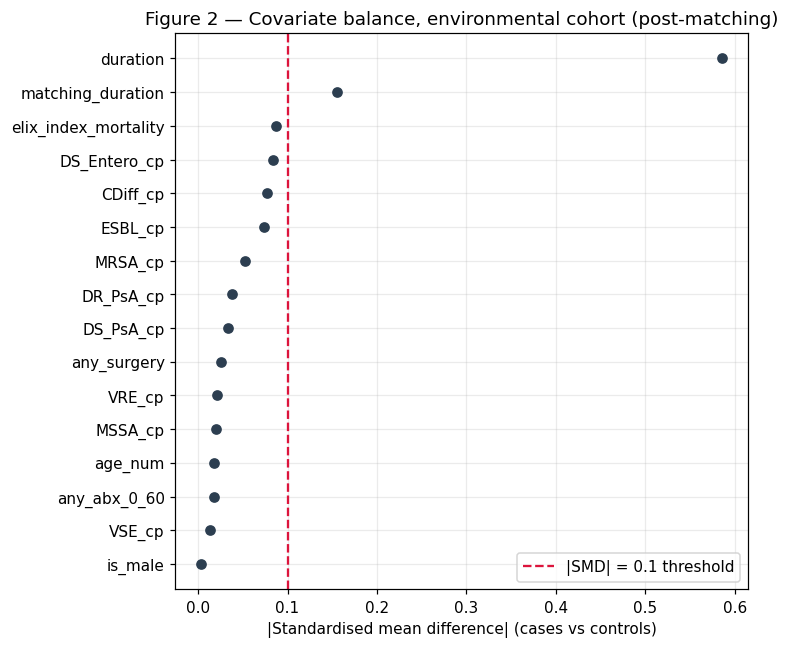

In [ ]:
def love_data(frame, variables, binary_set):
    ca, co = frame[frame.group_binary == 1], frame[frame.group_binary == 0]
    out = [(v, abs(smd(ca[v], co[v], binary=(v in binary_set)))) for v in variables]
    return pd.DataFrame(out, columns=["variable", "abs_SMD"]).sort_values("abs_SMD")

# [REV-1] matching_duration added to the Love plot below
bin_set = {"is_male", "any_surgery", "any_abx_0_60"}
love_env = love_data(env, ["age_num","is_male","any_surgery","any_abx_0_60",
                           "elix_index_mortality","duration","matching_duration"] + CP_COLS, bin_set)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(love_env["abs_SMD"], range(len(love_env)), color="#2c3e50", zorder=3)
ax.axvline(0.1, ls="--", color="crimson", label="|SMD| = 0.1 threshold")
ax.set_yticks(range(len(love_env))); ax.set_yticklabels(love_env["variable"])
ax.set_xlabel("|Standardised mean difference| (cases vs controls)")
ax.set_title("Figure 2 — Covariate balance, environmental cohort (post-matching)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/fig2_love_plot.png", bbox_inches="tight"); plt.show()


## 6. Univariable conditional logistic regression (Tables III and IV)

Paired t, Wilcoxon and McNemar tests assume 1:1 pairing. Matching here is variable-ratio
(1 to at most 3), so a case may have several controls and there is no unique pair to difference.
The estimator that respects the matched design and generalises to variable-ratio sets is
univariable conditional logistic regression, fitted one predictor at a time and stratified on
the matched set. Unadjusted associations that survive this screen motivate the multivariable
models.

In [ ]:
def univariable(frame, predictors, standardize=None):
    rows = []
    for p in predictors:
        std = [p] if (standardize and p in standardize) else None
        tidy, dropped, n, *_ = fit_clogit(frame, [p], standardize=std)
        if tidy is not None:
            r = tidy.iloc[0].to_dict(); r["n"] = n; rows.append(r)
        else:
            rows.append(dict(variable=p, OR=np.nan, CI_low=np.nan, CI_high=np.nan,
                             p=np.nan, n=n))
    return pd.DataFrame(rows)

uni_env = univariable(env, CP_COLS, standardize=CP_COLS if STANDARDIZE_CP else None)
uni_pat = univariable(pat, ABX_COLS)
uni_env.to_csv(f"{OUTPUT_DIR}/tableIII_univariable_environmental.csv", index=False)
uni_pat.to_csv(f"{OUTPUT_DIR}/tableIV_univariable_patient.csv", index=False)
print("=== TABLE III — Univariable, colonization pressure"
      + (" (per 1 SD)" if STANDARDIZE_CP else "") + " ==="); display(pretty(uni_env, sort=True))
print("=== TABLE IV — Univariable, antibiotic classes (per course) ==="); display(pretty(uni_pat, sort=True))


=== TABLE III — Univariable, colonization pressure (per 1 SD) ===


,variable,OR,95% CI,p
0,DS_Entero_cp,0.915,0.897 – 0.934,<0.001
1,CDiff_cp,0.921,0.903 – 0.939,<0.001
2,ESBL_cp,0.926,0.908 – 0.945,<0.001
3,MRSA_cp,0.946,0.927 – 0.964,<0.001
4,DR_PsA_cp,0.964,0.946 – 0.983,<0.001
5,DS_PsA_cp,0.970,0.952 – 0.99,0.003
6,VRE_cp,1.023,1.003 – 1.042,0.02
7,MSSA_cp,1.021,1.002 – 1.041,0.03
8,VSE_cp,1.015,0.996 – 1.034,0.134


=== TABLE IV — Univariable, antibiotic classes (per course) ===


,variable,OR,95% CI,p
0,anti_Cdiff_0_60,0.725,0.574 – 0.916,0.007
1,glycopeptide_0_60,0.758,0.633 – 0.907,0.002
2,lincosamide_0_60,0.799,0.617 – 1.034,0.088
3,tetracycline_0_60,0.829,0.763 – 0.902,<0.001
4,fluoroquinolone_0_60,0.847,0.802 – 0.895,<0.001
5,anti_staph_beta_lactam_0_60,0.859,0.637 – 1.158,0.318
6,cephalosporin_0_60,0.877,0.828 – 0.928,<0.001
7,penicillin_0_60,0.889,0.787 – 1.005,0.059
8,sulfonamide_0_60,0.891,0.833 – 0.953,<0.001
9,extended_spectrum_cephalosporin_0_60,0.903,0.791 – 1.031,0.131


## 7. Multivariable conditional logistic regression (Tables V and VI)

The environmental model (Table V) contains the nine CP variables together with age, sex,
surgery and the Elixhauser index. Sex and surgery are matching variables in this cohort and are
dropped automatically for lack of within-set variation; the drop is reported.

The patient model (Table VI) contains the antibiotic classes together with age, sex, surgery
and the Elixhauser index. Age, sex and surgery are not matched in this cohort, so they remain
as confounders.

In [ ]:
# --- Environmental model (Table 3) ---
env_preds = CP_COLS + BASE_COVARS
t3, drop3, n3, llf3, k3, res3 = fit_clogit(env, env_preds,
                                           standardize=CP_COLS if STANDARDIZE_CP else None)
print(f"Environmental model: n={n3:,} obs")
print("Covariates dropped by matching:", [d for d in drop3])
t3.to_csv(f"{OUTPUT_DIR}/tableV_environmental_model.csv", index=False)
print("=== TABLE V — Adjusted CP effects"
      + (" (per 1 SD)" if STANDARDIZE_CP else "") + " ==="); display(pretty(t3, sort=True))

# --- Patient model (Table 4) ---
pat_preds = ABX_COLS + BASE_COVARS
t4, drop4, n4, llf4, k4, res4 = fit_clogit(pat, pat_preds)
print(f"\nPatient model: n={n4:,} obs; dropped:", [d for d in drop4])
t4.to_csv(f"{OUTPUT_DIR}/tableVI_patient_model.csv", index=False)
print("=== TABLE VI — Adjusted antibiotic effects (per course) ==="); display(pretty(t4, sort=True))


Environmental model: n=52,936 obs
Covariates dropped by matching: [('is_male', 'matched (no within-set variation)'), ('any_surgery', 'matched (no within-set variation)')]
=== TABLE V — Adjusted CP effects (per 1 SD) ===


,variable,OR,95% CI,p
0,DS_Entero_cp,0.873,0.846 – 0.901,<0.001
1,VSE_cp,1.088,1.059 – 1.118,<0.001
2,MSSA_cp,1.082,1.057 – 1.107,<0.001
3,ESBL_cp,0.939,0.914 – 0.964,<0.001
4,CDiff_cp,0.945,0.925 – 0.965,<0.001
5,VRE_cp,1.051,1.027 – 1.076,<0.001
6,MRSA_cp,0.965,0.943 – 0.989,0.004
7,age_num,1.026,1.012 – 1.04,<0.001
8,DR_PsA_cp,0.993,0.971 – 1.015,0.513
9,DS_PsA_cp,1.007,0.982 – 1.033,0.579



Patient model: n=67,328 obs; dropped: []
=== TABLE VI — Adjusted antibiotic effects (per course) ===


,variable,OR,95% CI,p
0,anti_Cdiff_0_60,0.727,0.572 – 0.925,0.009
1,any_surgery,1.261,1.199 – 1.327,<0.001
2,glycopeptide_0_60,0.745,0.61 – 0.909,0.004
3,lincosamide_0_60,0.844,0.642 – 1.108,0.221
4,fluoroquinolone_0_60,0.864,0.816 – 0.914,<0.001
5,tetracycline_0_60,0.868,0.796 – 0.946,0.001
6,anti_staph_beta_lactam_0_60,0.880,0.639 – 1.212,0.435
7,anti_anaerobe_0_60,1.106,0.955 – 1.281,0.18
8,cephalosporin_0_60,0.904,0.853 – 0.958,<0.001
9,carbapenem_0_60,1.084,0.851 – 1.381,0.513


### 7b. Adjustment for length of stay [REV-1]

Reviewer comment 1 noted a marked imbalance in duration of hospital or room stay between cases
and controls (SMD 0.586 and 0.605), observed that conditional regression alone does not remove
this time-dependent bias, and asked for the duration of stay to be incorporated into the model,
for an analysis based on duration of risk, or for a landmark or time-dependent sensitivity
analysis. Sections 7b and 7c address this in turn.

One clarification affects the size of the problem. `duration` is total room occupancy, and its
SMD of 0.586 and 0.605 is the figure quoted, taken from Table I. `matching_duration` is the
aligned observation window on which the matching was performed, and its SMD is much smaller
(printed in section 4). Reporting `duration` alone therefore overstated the imbalance on the
matched quantity. The residual imbalance on `matching_duration` is nonetheless above the 0.10
threshold, so adjustment remains warranted.

Both adjustments are fitted below. Adjusting for total `duration` is arguably an
over-adjustment: for a case, occupancy is partly determined by when the index culture was
taken, so `duration` lies on the pathway between exposure and outcome rather than before it,
and conditioning on it removes part of the outcome. It is reported regardless.

In [ ]:
# [REV-1] ---- models adjusted for length of stay ---------------------------
dur_rows = []
def _add_dur(label, tidy, n, pick):
    if tidy is None: return
    r = tidy[tidy["variable"] == pick]
    if not len(r): return
    r = r.iloc[0]
    dur_rows.append(dict(Model=label, n=f"{n:,}", Variable=pick, OR=round(r.OR, 3),
                         CI=f"{r.CI_low:.3f}-{r.CI_high:.3f}",
                         p=("<0.001" if r.p < 1e-3 else round(r.p, 3))))

TOP_CP  = "DS_Entero_cp"            # leading environmental effect in the primary model
TOP_ABX = "anti_Cdiff_0_60"         # leading antibiotic effect in the primary model

# --- environmental cohort ---
_add_dur("ENV primary (no duration term)", t3, n3, TOP_CP)
for dv in ["matching_duration", "duration"]:
    tt, _, nn, *_ = fit_clogit(env, CP_COLS + BASE_COVARS + [dv],
                               standardize=CP_COLS if STANDARDIZE_CP else None)
    _add_dur(f"ENV + {dv}", tt, nn, TOP_CP)
    _add_dur(f"   (effect of {dv} itself)", tt, nn, dv)

# --- patient cohort ---
_add_dur("PAT primary (no duration term)", t4, n4, TOP_ABX)
for dv in ["matching_duration", "duration"]:
    tt, _, nn, *_ = fit_clogit(pat, ABX_COLS + BASE_COVARS + [dv])
    _add_dur(f"PAT + {dv}", tt, nn, TOP_ABX)
    _add_dur(f"   (effect of {dv} itself)", tt, nn, dv)

dur_tbl = pd.DataFrame(dur_rows)
dur_tbl.to_csv(f"{OUTPUT_DIR}/tableXIII_duration_adjusted.csv", index=False)
print("=== TABLE XIII — Length-of-stay adjusted models [REV-1] ===")
display(dur_tbl)
print("Reading: whether the leading estimate moves once stay length enters the model.")

=== TABLE XIII — Length-of-stay adjusted models [REV-1] ===


,Model,n,Variable,OR,CI,p
0,ENV primary (no duration term),"52,936",DS_Entero_cp,0.873,0.846-0.901,<0.001
1,ENV + matching_duration,"52,936",DS_Entero_cp,0.876,0.849-0.904,<0.001
2,(effect of matching_duration itself),"52,936",matching_duration,1.135,1.107-1.164,<0.001
3,ENV + duration,"52,936",DS_Entero_cp,0.938,0.905-0.972,<0.001
4,(effect of duration itself),"52,936",duration,1.855,1.815-1.896,<0.001
5,PAT primary (no duration term),"67,328",anti_Cdiff_0_60,0.727,0.572-0.925,0.009
6,PAT + matching_duration,"67,328",anti_Cdiff_0_60,0.739,0.581-0.942,0.014
7,(effect of matching_duration itself),"67,328",matching_duration,1.159,1.140-1.179,<0.001
8,PAT + duration,"67,328",anti_Cdiff_0_60,0.733,0.549-0.978,0.035
9,(effect of duration itself),"67,328",duration,1.689,1.664-1.715,<0.001


Reading: whether the leading estimate moves once stay length enters the model.


### 7c. Landmark analysis [REV-1]

Adjusting for a covariate cannot fully remove differential observation time. A case must remain
in the room long enough to be cultured, so cases are by construction patients who were observed
for longer.

A landmark analysis removes that asymmetry by restricting to matched sets in which every
member, case and controls alike, remained for at least L days. Within such a set all members
had comparable opportunity both to be exposed and to be detected, so the surviving contrast is
not driven by one group being observed longer than another.

The analysis is repeated at L = 3, 5 and 7 days. Power falls as L rises because fewer matched
sets remain eligible, so the confidence intervals widen and the L = 7 result in particular is
indicative only. The pattern across the three landmarks is what is interpreted, rather than any
single estimate.

In [ ]:
# [REV-1] ---- landmark analysis: every set member observed >= L days -------
land_rows = []
for L in LANDMARK_DAYS:
    # keep a matched set only if its SHORTEST-staying member reached the landmark
    e_ok = env.groupby("stratum")["matching_duration"].transform("min") >= L
    p_ok = pat.groupby("stratum")["matching_duration"].transform("min") >= L
    e_sub, p_sub = env[e_ok], pat[p_ok]

    te, _, ne, *_ = fit_clogit(e_sub, CP_COLS + BASE_COVARS,
                               standardize=CP_COLS if STANDARDIZE_CP else None)
    if te is not None and (te.variable == TOP_CP).any():
        r = te[te.variable == TOP_CP].iloc[0]
        land_rows.append(dict(Cohort="Environmental", Landmark=f">= {L} days",
                              Sets=f"{e_sub['stratum'].nunique():,}", n=f"{ne:,}",
                              Variable=TOP_CP, OR=round(r.OR, 3),
                              CI=f"{r.CI_low:.3f}-{r.CI_high:.3f}",
                              p=("<0.001" if r.p < 1e-3 else round(r.p, 3))))

    tp, _, np_, *_ = fit_clogit(p_sub, ABX_COLS + BASE_COVARS)
    if tp is not None and (tp.variable == TOP_ABX).any():
        r = tp[tp.variable == TOP_ABX].iloc[0]
        land_rows.append(dict(Cohort="Patient", Landmark=f">= {L} days",
                              Sets=f"{p_sub['stratum'].nunique():,}", n=f"{np_:,}",
                              Variable=TOP_ABX, OR=round(r.OR, 3),
                              CI=f"{r.CI_low:.3f}-{r.CI_high:.3f}",
                              p=("<0.001" if r.p < 1e-3 else round(r.p, 3))))
    else:
        # record non-estimability rather than silently dropping the row: a rare
        # exposure can lose all within-stratum variation once the cohort is restricted
        land_rows.append(dict(Cohort="Patient", Landmark=f">= {L} days",
                              Sets=f"{p_sub['stratum'].nunique():,}", n=f"{np_:,}",
                              Variable=TOP_ABX, OR=np.nan,
                              CI="not estimable (no within-set variation)", p=np.nan))

land_tbl = pd.DataFrame(land_rows).sort_values(["Cohort", "Landmark"])
land_tbl.to_csv(f"{OUTPUT_DIR}/tableXIV_landmark.csv", index=False)
print("=== TABLE XIV — Landmark analysis [REV-1] ===")
display(land_tbl)
print("Reading: an association robust to the landmark is unlikely to be an artefact of")
print("      differential observation time; one that attenuates to the null may be.")

=== TABLE XIV — Landmark analysis [REV-1] ===


,Cohort,Landmark,Sets,n,Variable,OR,CI,p
0,Environmental,>= 3 days,"11,964","33,722",DS_Entero_cp,0.854,0.822-0.887,<0.001
2,Environmental,>= 5 days,"5,158","13,139",DS_Entero_cp,0.842,0.794-0.893,<0.001
4,Environmental,>= 7 days,"2,514","5,948",DS_Entero_cp,0.847,0.775-0.926,<0.001
1,Patient,>= 3 days,"12,382","40,565",anti_Cdiff_0_60,0.828,0.646-1.062,0.138
3,Patient,>= 5 days,"5,116","15,148",anti_Cdiff_0_60,0.907,0.638-1.290,0.587
5,Patient,>= 7 days,"2,423","6,345",anti_Cdiff_0_60,1.126,0.581-2.185,0.725


Reading: an association robust to the landmark is unlikely to be an artefact of
      differential observation time; one that attenuates to the null may be.


### 7d. Both exposures on a common scale [REV-4]

Reviewer comment 4 noted that calculating effects in the two cohorts on different scales, per
standard deviation and per antibiotic course, and comparing them by absolute log odds ratio
does not permit direct clinical interpretation.

Revision 0 compared colonization pressure per 1 SD against antibiotics per treatment course and
ranked the two by |log OR|. Those units are not commensurable, so the ranking was determined by
the choice of units rather than by the data.

The distortion is large because the leading antibiotic exposures are rare. When a drug reaches
a fraction of a percent of the cohort, its standard deviation is far below one course, so a
per-course contrast describes a shift of many standard deviations while a per-SD contrast
describes a fraction of a course. The relationship between the two is exact:

$$\log \text{OR}_{\text{per SD}} \;=\; \log \text{OR}_{\text{per course}} \times \text{SD}$$

The cell below refits the patient model with the antibiotic counts standardised, so that both
pathways are expressed per 1 SD of their own exposure, and prints the exposure prevalences that
drive the divergence. This alters the answer to the primary research question; the change is
reported in section 12.

In [ ]:
# [REV-4] ---- both exposures on a common per-SD scale ----------------------
t6_sd, _, n6sd, *_ = fit_clogit(pat, ABX_COLS + BASE_COVARS,
                                standardize=ABX_COLS if STANDARDIZE_ABX else None)
t6_sd.to_csv(f"{OUTPUT_DIR}/tableXV_patient_model_perSD.csv", index=False)
print(f"=== TABLE XV — Patient model, antibiotics per 1 SD [REV-4] (n={n6sd:,}) ===")
display(pretty(t6_sd, sort=True))

def _rank(tidy, keep, label):
    t = tidy[tidy.variable.isin(keep)].copy()
    t["abs_logOR"] = np.abs(np.log(t["OR"]))
    t = t.sort_values("abs_logOR", ascending=False)
    t["cohort"] = label
    return t[["cohort", "variable", "OR", "CI_low", "CI_high", "p", "abs_logOR"]]

cmp_sd = pd.concat([_rank(t3, CP_COLS, "Environmental (per 1 SD)").head(3),
                    _rank(t6_sd, ABX_COLS, "Patient (per 1 SD)").head(3)])
cmp_sd.to_csv(f"{OUTPUT_DIR}/tableXV_common_scale_comparison.csv", index=False)
print("\n=== Common-scale comparison: leading effects, both per 1 SD [REV-4] ===")
display(cmp_sd.round(4))

env_mag = float(_rank(t3, CP_COLS, "e")["abs_logOR"].iloc[0])
pat_mag = float(_rank(t6_sd, ABX_COLS, "p")["abs_logOR"].iloc[0])
STRONGER_SD = "environmental colonization pressure" if env_mag > pat_mag else "prior antibiotic exposure"
print(f"\nLeading |log OR| per SD -> environmental {env_mag:.3f} vs antibiotic {pat_mag:.3f}")
print(f"On a common scale the larger association is: {STRONGER_SD}")

# why the two scalings disagree: the leading antibiotics are rare exposures
print("\n--- [REV-4] why per-course and per-SD disagree ---")
rows = []
for c in ABX_COLS:
    s = pd.to_numeric(pat[c], errors="coerce")
    pc = t4.loc[t4.variable == c, "OR"]
    sd_ = t6_sd.loc[t6_sd.variable == c, "OR"]
    if len(pc) and len(sd_):
        rows.append(dict(Antibiotic=c, SD=round(s.std(), 4),
                         pct_exposed=round(100 * (s > 0).mean(), 2),
                         OR_per_course=round(float(pc.iloc[0]), 3),
                         OR_per_SD=round(float(sd_.iloc[0]), 3),
                         check_logOR_perSD=round(np.log(float(pc.iloc[0])) * s.std(), 4),
                         actual_logOR_perSD=round(np.log(float(sd_.iloc[0])), 4)))
scale_tbl = pd.DataFrame(rows).sort_values("pct_exposed")
scale_tbl.to_csv(f"{OUTPUT_DIR}/diag_scale_conversion.csv", index=False)
display(scale_tbl)
print("The last two columns agree by construction: log OR per SD = log OR per course x SD.")

=== TABLE XV — Patient model, antibiotics per 1 SD [REV-4] (n=67,328) ===


,variable,OR,95% CI,p
0,any_surgery,1.261,1.199 – 1.327,<0.001
1,is_male,1.053,1.016 – 1.091,0.004
2,fluoroquinolone_0_60,0.948,0.929 – 0.968,<0.001
3,tetracycline_0_60,0.965,0.945 – 0.986,0.001
4,glycopeptide_0_60,0.966,0.944 – 0.989,0.004
5,cephalosporin_0_60,0.966,0.947 – 0.985,<0.001
6,anti_Cdiff_0_60,0.971,0.949 – 0.993,0.01
7,sulfonamide_0_60,0.979,0.96 – 0.999,0.037
8,lincosamide_0_60,0.987,0.967 – 1.008,0.223
9,anti_anaerobe_0_60,1.012,0.994 – 1.03,0.186



=== Common-scale comparison: leading effects, both per 1 SD [REV-4] ===


,cohort,variable,OR,CI_low,CI_high,p,abs_logOR
2,Environmental (per 1 SD),DS_Entero_cp,0.8731,0.8463,0.9008,0.0000,0.1357
8,Environmental (per 1 SD),VSE_cp,1.0882,1.0595,1.1176,0.0000,0.0845
6,Environmental (per 1 SD),MSSA_cp,1.0816,1.0568,1.1070,0.0000,0.0784
7,Patient (per 1 SD),fluoroquinolone_0_60,0.9484,0.9290,0.9681,0.0000,0.0530
13,Patient (per 1 SD),tetracycline_0_60,0.9653,0.9448,0.9863,0.0013,0.0353
8,Patient (per 1 SD),glycopeptide_0_60,0.9660,0.9437,0.9887,0.0036,0.0346



Leading |log OR| per SD -> environmental 0.136 vs antibiotic 0.053
On a common scale the larger association is: environmental colonization pressure

--- [REV-4] why per-course and per-SD disagree ---


,Antibiotic,SD,pct_exposed,OR_per_course,OR_per_SD,check_logOR_perSD,actual_logOR_perSD
3,carbapenem_0_60,0.0771,0.06,1.084,1.006,0.0062,0.0059
2,anti_staph_beta_lactam_0_60,0.0667,0.10,0.880,0.991,-0.0085,-0.0092
0,anti_Cdiff_0_60,0.0942,0.21,0.727,0.971,-0.0300,-0.0297
9,lincosamide_0_60,0.0765,0.23,0.844,0.987,-0.0130,-0.0130
8,glycopeptide_0_60,0.1164,0.26,0.745,0.966,-0.0343,-0.0346
5,extended_spectrum_cephalosporin_0_60,0.1431,0.27,1.018,1.003,0.0025,0.0028
1,anti_anaerobe_0_60,0.1185,0.42,1.106,1.012,0.0119,0.0117
11,penicillin_0_60,0.1551,0.50,0.945,0.991,-0.0088,-0.0087
10,macrolide_0_60,0.1552,0.64,0.956,0.993,-0.0071,-0.0072
6,extended_spectrum_penicillin_0_60,0.2315,1.30,0.973,0.993,-0.0064,-0.0066


The last two columns agree by construction: log OR per SD = log OR per course x SD.


## 8. Model diagnostics

Three checks are run. Multicollinearity is assessed by variance inflation factors on the
standardised predictor matrix, with VIF below 5 taken as acceptable. Linearity of continuous
effects is assessed by a likelihood-ratio test of a natural-cubic-spline age term against a
linear age term, where a significant result indicates non-linearity worth modelling with
splines. Influence is assessed by leave-one-pathogen-out refitting of the environmental model,
which shows whether any single pathogen cohort drives the pooled CP estimates.

In [ ]:
# --- 8.1 VIF ---
def vif_table(frame, cols, standardize=True):
    X = frame[cols].apply(pd.to_numeric, errors="coerce").dropna()
    keepc = [c for c in cols if X[c].std() > 0]      # drop constant columns (guards FAST_MODE subsamples)
    X = X[keepc]
    if standardize: X = X.apply(lambda s: (s - s.mean()) / s.std())
    X = sm.add_constant(X)
    return pd.DataFrame({"variable": keepc,
                         "VIF": [round(variance_inflation_factor(X.values, i), 2)
                                 for i in range(1, X.shape[1])]}).sort_values("VIF", ascending=False)
print("=== TABLE VII — VIF, colonization pressure ==="); display(vif_table(env, CP_COLS))
print("=== TABLE VIII — VIF, antibiotic classes ===");    display(vif_table(pat, ABX_COLS))

# --- 8.2 Linearity of age (environmental cohort) ---
try:
    cpv = next((c for c in CP_COLS if env[c].std() > 0), CP_COLS[0])   # a CP column that actually varies
    sub = env.dropna(subset=["age_num", cpv]).copy()
    g = sub["stratum"].values; y = sub["group_binary"].values
    z = lambda s: (s - s.mean()) / (s.std() if s.std() > 0 else 1.0)
    X_lin = np.column_stack([z(sub[cpv]).values, sub["age_num"].values])
    r_lin = ConditionalLogit(y, X_lin, groups=g).fit(disp=0)
    spl   = dmatrix("cr(age, df=4) - 1", {"age": sub["age_num"].values}, return_type="dataframe")
    X_spl = np.column_stack([z(sub[cpv]).values, spl.values])
    r_spl = ConditionalLogit(y, X_spl, groups=g).fit(disp=0)
    lr = 2 * (r_spl.llf - r_lin.llf); ddf = X_spl.shape[1] - X_lin.shape[1]
    p_lin = stats.chi2.sf(lr, ddf)
    aic = lambda res, k: -2 * res.llf + 2 * k
    print(f"\nAge linearity LRT (spline vs linear): chi2={lr:.2f}, df={ddf}, p={p_lin:.4f}")
    print(f"AIC linear={aic(r_lin, X_lin.shape[1]):.1f}  vs  spline={aic(r_spl, X_spl.shape[1]):.1f}")
    print("=> " + ("non-linear age effect detected; consider a spline in a final model."
                   if p_lin < 0.05 else "linear age assumption is adequate."))
except Exception as e:
    print("Age linearity check skipped:", e)

# --- 8.3 Leave-one-pathogen-out robustness of the environmental model ---
runs = sorted(env["run"].unique())
top_cp = t3.reindex(t3["OR"].sub(1).abs().sort_values(ascending=False).index)["variable"].head(3).tolist()
top_cp = [c for c in top_cp if c in CP_COLS]
loo_rows = []
for rn in runs:
    sub = env[env["run"] != rn]
    tt, *_ = fit_clogit(sub, CP_COLS + BASE_COVARS, standardize=CP_COLS if STANDARDIZE_CP else None)
    if tt is not None:
        rec = {"excluded_run": rn}
        for c in top_cp:
            v = tt.loc[tt.variable == c, "OR"]
            rec[c + "_OR"] = round(float(v.iloc[0]), 3) if len(v) else np.nan
        loo_rows.append(rec)
loo = pd.DataFrame(loo_rows)
loo.to_csv(f"{OUTPUT_DIR}/tableIX_leave_one_pathogen_out.csv", index=False)
print("\n=== TABLE IX — Leave-one-pathogen-out OR stability ==="); display(loo)


=== TABLE VII — VIF, colonization pressure ===


,variable,VIF
2,DS_Entero_cp,2.58
8,VSE_cp,2.03
4,ESBL_cp,1.94
3,DS_PsA_cp,1.85
5,MRSA_cp,1.64
7,VRE_cp,1.55
6,MSSA_cp,1.51
1,DR_PsA_cp,1.40
0,CDiff_cp,1.19


=== TABLE VIII — VIF, antibiotic classes ===


,variable,VIF
8,glycopeptide_0_60,1.33
5,extended_spectrum_cephalosporin_0_60,1.26
3,carbapenem_0_60,1.11
7,fluoroquinolone_0_60,1.06
13,tetracycline_0_60,1.05
12,sulfonamide_0_60,1.05
6,extended_spectrum_penicillin_0_60,1.04
4,cephalosporin_0_60,1.04
1,anti_anaerobe_0_60,1.03
2,anti_staph_beta_lactam_0_60,1.03


Age linearity check skipped: need covariance of parameters for computing (unnormalized) covariances

=== TABLE IX — Leave-one-pathogen-out OR stability ===


,excluded_run,DS_Entero_cp_OR,VSE_cp_OR,MSSA_cp_OR
0,C_diff,0.874,1.086,1.087
1,DR_P_aeruginosa,0.875,1.093,1.084
2,DS_E_cloacae,0.875,1.082,1.083
3,DS_E_coli,0.830,1.103,1.092
4,DS_K_oxytoca,0.871,1.085,1.079
5,DS_K_pneumoniae,0.866,1.088,1.092
6,DS_P_aeruginosa,0.873,1.089,1.084
7,DS_P_mirabilis,0.862,1.091,1.084
8,DS_S_marcescens,0.877,1.088,1.079
9,ESBL_E_cloacae,0.873,1.087,1.081


## 9. Interaction analysis (exploratory)

Interactions of colonization pressure with antibiotic exposure, age and surgery are of
interest. The matched design constrains where they can be estimated: in the environmental
cohort both antibiotics and surgery are matching variables and have no within-set variation, so
CP by antibiotic and CP by surgery interactions cannot be identified there. They can be
examined in the patient cohort, where colonization pressure is not a matching variable and
varies alongside antibiotic exposure. Each interaction is tested by adding CP by modifier
product terms to the patient model.

Because 36 product terms are tested, Bonferroni-adjusted p values and Benjamini-Hochberg q
values are reported alongside the nominal p values, and the results are treated as exploratory.

In [ ]:
def interaction_test(frame, cp_list, modifier, modifier_is_col=True, standardize_cp=True):
    """Add CP x modifier product terms to a patient-cohort clogit and report them."""
    d = frame.copy()
    preds = list(cp_list) + [modifier] + BASE_COVARS
    # build standardized CP, then products
    extra = []
    for c in cp_list:
        cz = pd.to_numeric(d[c], errors="coerce")
        if standardize_cp:
            s = cz.std(); cz = (cz - cz.mean()) / s if s > 0 else cz * 0
        d[c + "__z"] = cz
        m = pd.to_numeric(d[modifier], errors="coerce")
        d[f"{c}_x_{modifier}"] = cz * m
        extra.append(f"{c}_x_{modifier}")
    use = [c + "__z" for c in cp_list] + [modifier] + BASE_COVARS + extra
    tidy, dropped, n, *_ = fit_clogit(d, use)   # already standardized -> no re-scale
    if tidy is None: return None
    inter = tidy[tidy["variable"].str.contains("_x_")].copy()
    return inter

modifiers = ["age_num", "any_surgery"]
for ab in ["carbapenem_0_60", "fluoroquinolone_0_60"]:
    if ab in pat.columns: modifiers.append(ab)

inter_all = []
for mod in modifiers:
    res = interaction_test(pat, CP_COLS, mod)
    if res is not None and len(res):
        res["modifier"] = mod
        inter_all.append(res)
inter_df = pd.concat(inter_all, ignore_index=True) if inter_all else pd.DataFrame()
if len(inter_df):
    # [REV-minor] multiple-testing correction across ALL interaction terms tested
    mtot = len(inter_df)
    inter_df = inter_df.sort_values("p").reset_index(drop=True)
    inter_df["p_bonferroni"] = np.minimum(inter_df["p"] * mtot, 1.0)
    # Benjamini-Hochberg step-up FDR
    ranks = np.arange(1, mtot + 1)
    bh_raw = inter_df["p"].values * mtot / ranks
    inter_df["q_BH"] = np.minimum.accumulate(bh_raw[::-1])[::-1].clip(0, 1)
    inter_df["survives_correction"] = np.where(
        (inter_df["p_bonferroni"] < 0.05) | (inter_df["q_BH"] < 0.05), "YES", "no")
    inter_df.to_csv(f"{OUTPUT_DIR}/tableX_interactions_patient.csv", index=False)

    nominal = inter_df[inter_df["p"] < 0.05]
    survive = inter_df[inter_df["survives_correction"] == "YES"]
    print(f"=== TABLE X — CP x modifier interactions [REV-minor] ===")
    print(f"  terms tested                         : {mtot}")
    print(f"  nominally significant (p<0.05)       : {len(nominal)}")
    print(f"  expected by chance alone at alpha=.05: {0.05*mtot:.1f}")
    print(f"  Bonferroni threshold                 : {0.05/mtot:.5f}")
    print(f"  surviving either correction          : {len(survive)}")
    cols = ["variable", "modifier", "OR", "CI_low", "CI_high", "p", "p_bonferroni",
            "q_BH", "survives_correction"]
    display(inter_df[cols].head(10).round(4))
    if len(survive) == 0:
        print("\n=> NO interaction survives correction for multiplicity.")
        print("   These are exploratory, hypothesis-generating findings only.")
else:
    print("No interaction terms could be estimated.")


=== TABLE X — CP x modifier interactions [REV-minor] ===
  terms tested                         : 36
  nominally significant (p<0.05)       : 4
  expected by chance alone at alpha=.05: 1.8
  Bonferroni threshold                 : 0.00139
  surviving either correction          : 0


,variable,modifier,OR,CI_low,CI_high,p,p_bonferroni,q_BH,survives_correction
0,DR_PsA_cp_x_age_num,age_num,1.0014,1.0002,1.0026,0.0239,0.8602,0.3205,no
1,MRSA_cp_x_any_surgery,any_surgery,1.0735,1.0075,1.1438,0.0286,1.0000,0.3205,no
2,VRE_cp_x_age_num,age_num,0.9987,0.9974,1.0000,0.0452,1.0000,0.3205,no
3,VSE_cp_x_carbapenem_0_60,carbapenem_0_60,0.3512,0.1259,0.9798,0.0456,1.0000,0.3205,no
4,DR_PsA_cp_x_any_surgery,any_surgery,0.9394,0.8809,1.0017,0.0565,1.0000,0.3205,no
5,DS_PsA_cp_x_any_surgery,any_surgery,0.9364,0.8749,1.0022,0.0579,1.0000,0.3205,no
6,DS_Entero_cp_x_carbapenem_0_60,carbapenem_0_60,2.9123,0.9464,8.9612,0.0623,1.0000,0.3205,no
7,MRSA_cp_x_fluoroquinolone_0_60,fluoroquinolone_0_60,0.9457,0.8866,1.0089,0.0905,1.0000,0.4074,no
8,DR_PsA_cp_x_carbapenem_0_60,carbapenem_0_60,0.1985,0.0254,1.5488,0.1229,1.0000,0.4346,no
9,CDiff_cp_x_age_num,age_num,0.9991,0.9979,1.0003,0.1231,1.0000,0.4346,no



=> NO interaction survives correction for multiplicity.
   These are exploratory, hypothesis-generating findings only.


## 10. Sensitivity analyses (Table XI)

Four analyses were pre-specified. The comorbidity specification is varied by replacing the
Elixhauser summary score with the full set of individual comorbidity indicators, to test
whether the summary score captures comorbidity confounding adequately. The models are then
refitted within the resistant-pathogen cohorts alone and within the susceptible-pathogen
cohorts alone. Finally, the leading environmental and antibiotic effects are estimated
separately within each pathogen run, which addresses whether the associations are consistent
across pathogens.

In [ ]:
sens_rows = []
def add_sens(label, tidy, pick):
    if tidy is None: return
    r = tidy[tidy["variable"] == pick]
    if len(r):
        r = r.iloc[0]
        sens_rows.append(dict(analysis=label, variable=pick, OR=round(r.OR,3),
                              CI=f"{r.CI_low:.3f}–{r.CI_high:.3f}",
                              p=("<0.001" if r.p<1e-3 else round(r.p,3))))

# pick the strongest signals from the primary models to track across sensitivity analyses
top_cp_var  = t3.reindex(t3.OR.sub(1).abs().sort_values(ascending=False).index)
top_cp_var  = top_cp_var[top_cp_var.variable.isin(CP_COLS)].variable.iloc[0]
top_abx_var = t4.reindex(t4.OR.sub(1).abs().sort_values(ascending=False).index)
top_abx_var = top_abx_var[top_abx_var.variable.isin(ABX_COLS)].variable.iloc[0]
print("Tracking top CP effect:", top_cp_var, "| top antibiotic effect:", top_abx_var)

# --- S1: Elixhauser score vs individual comorbidities (environmental) ---
s1a, *_ = fit_clogit(env, CP_COLS + ["age_num","is_male","any_surgery","elix_index_mortality"],
                     standardize=CP_COLS if STANDARDIZE_CP else None)
add_sens("Env: Elixhauser score", s1a, top_cp_var)
s1b, *_ = fit_clogit(env, CP_COLS + ["age_num","is_male","any_surgery"] + ELIX_COLS,
                     standardize=CP_COLS if STANDARDIZE_CP else None)
add_sens("Env: individual comorbidities", s1b, top_cp_var)

# --- S2/S3: resistant-only and susceptible-only ---
for lab, sub_env in [("resistant", env[env.resistant=="resistant"]),
                     ("susceptible", env[env.resistant=="susceptible"])]:
    tt, *_ = fit_clogit(sub_env, CP_COLS + BASE_COVARS,
                        standardize=CP_COLS if STANDARDIZE_CP else None)
    add_sens(f"Env: {lab} pathogens", tt, top_cp_var)
for lab, sub_pat in [("resistant", pat[pat.resistant=="resistant"]),
                     ("susceptible", pat[pat.resistant=="susceptible"])]:
    tt, *_ = fit_clogit(sub_pat, ABX_COLS + BASE_COVARS)
    add_sens(f"Pat: {lab} pathogens", tt, top_abx_var)

sens = pd.DataFrame(sens_rows)
sens.to_csv(f"{OUTPUT_DIR}/tableXI_sensitivity.csv", index=False)
print("=== TABLE XI — Sensitivity analyses ==="); display(sens)

# --- S4: pathogen-specific models (consistency across pathogens) ---
pathogen_rows = []
for rn in sorted(df["run"].unique()):
    e_sub = env[env.run == rn]; p_sub = pat[pat.run == rn]
    te, *_ = fit_clogit(e_sub, CP_COLS + BASE_COVARS,
                        standardize=CP_COLS if STANDARDIZE_CP else None)
    tp, *_ = fit_clogit(p_sub, ABX_COLS + BASE_COVARS)
    rec = dict(pathogen=rn, resistance=RUN_LABELS.get(rn, "other"))
    if te is not None and (te.variable == top_cp_var).any():
        row = te[te.variable == top_cp_var].iloc[0]
        rec[f"{top_cp_var}_OR"] = round(row.OR, 3); rec[f"{top_cp_var}_p"] = round(row.p, 3)
    if tp is not None and (tp.variable == top_abx_var).any():
        row = tp[tp.variable == top_abx_var].iloc[0]
        rec[f"{top_abx_var}_OR"] = round(row.OR, 3); rec[f"{top_abx_var}_p"] = round(row.p, 3)
    pathogen_rows.append(rec)
pathogen_specific = pd.DataFrame(pathogen_rows)
pathogen_specific.to_csv(f"{OUTPUT_DIR}/tableXII_pathogen_specific.csv", index=False)
print("\n=== TABLE XII — Pathogen-specific top effects ==="); display(pathogen_specific)


Tracking top CP effect: DS_Entero_cp | top antibiotic effect: anti_Cdiff_0_60
=== TABLE XI — Sensitivity analyses ===


,analysis,variable,OR,CI,p
0,Env: Elixhauser score,DS_Entero_cp,0.873,0.846–0.901,<0.001
1,Env: individual comorbidities,DS_Entero_cp,0.887,0.860–0.916,<0.001
2,Env: resistant pathogens,DS_Entero_cp,0.793,0.741–0.850,<0.001
3,Env: susceptible pathogens,DS_Entero_cp,0.899,0.868–0.932,<0.001
4,Pat: resistant pathogens,anti_Cdiff_0_60,0.913,0.631–1.322,0.629
5,Pat: susceptible pathogens,anti_Cdiff_0_60,0.587,0.408–0.844,0.004



=== TABLE XII — Pathogen-specific top effects ===


,pathogen,resistance,DS_Entero_cp_OR,DS_Entero_cp_p,anti_Cdiff_0_60_OR,anti_Cdiff_0_60_p
0,C_diff,other,0.813,0.031,1.850,0.348
1,DR_P_aeruginosa,resistant,0.831,0.085,0.074,0.455
2,DS_E_cloacae,susceptible,0.793,0.013,0.001,0.830
3,DS_E_coli,susceptible,1.094,0.016,0.482,0.043
4,DS_K_oxytoca,susceptible,0.937,0.508,0.002,0.741
5,DS_K_pneumoniae,susceptible,0.939,0.204,0.914,0.756
6,DS_P_aeruginosa,susceptible,0.878,0.019,0.406,0.201
7,DS_P_mirabilis,susceptible,1.140,0.081,0.556,0.586
8,DS_S_marcescens,susceptible,0.757,0.004,NaN,NaN
9,ESBL_E_cloacae,resistant,0.917,0.498,1.036,0.941


## 11. Figures

Figure 1 is the study flow. Figures 3 to 5 are forest plots on a logarithmic odds-ratio axis,
with the dashed line at OR = 1 marking the null. Figure 5 places the leading environmental and
patient effects on a single axis, both per 1 SD, so that their magnitudes can be compared
directly; it is the visual form of the answer to the primary question.

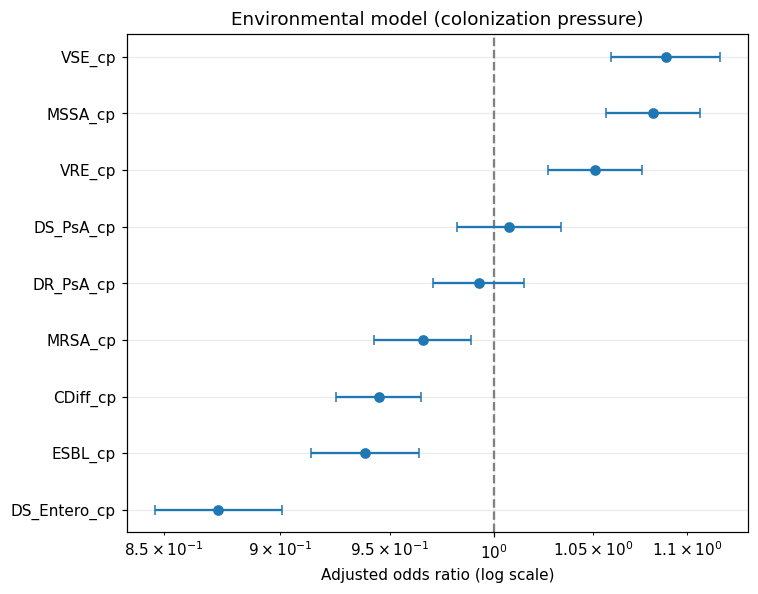

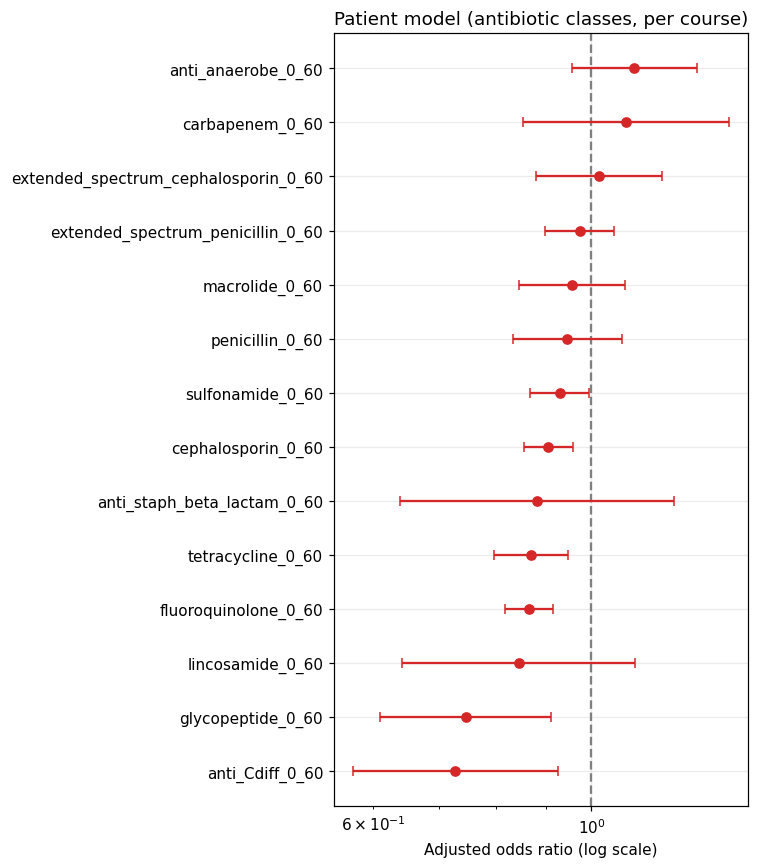

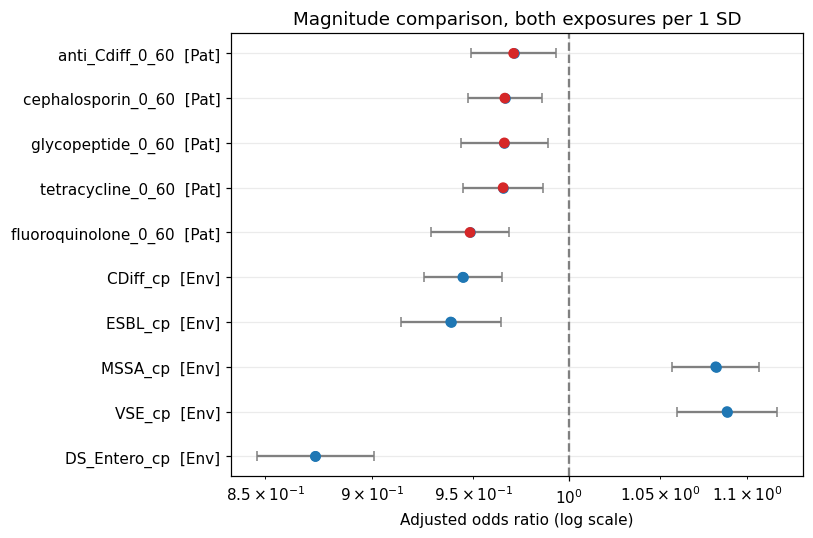

In [ ]:
# --- Figure 1: study flow diagram (numbers pulled from the data) ---


# --- forest-plot helper ---
def forest(tidy, title, fname, keep=None, color="#2c3e50"):
    t = tidy.dropna(subset=["OR"]).copy()
    if keep is not None: t = t[t.variable.isin(keep)]
    t = t.sort_values("OR")
    fig, ax = plt.subplots(figsize=(7, max(3, 0.5*len(t)+1)))
    y = np.arange(len(t))
    ax.errorbar(t["OR"], y, xerr=[t["OR"]-t["CI_low"], t["CI_high"]-t["OR"]],
                fmt="o", color=color, capsize=3, zorder=3)
    ax.axvline(1, ls="--", color="grey")
    ax.set_yticks(y); ax.set_yticklabels(t["variable"]); ax.set_xscale("log")
    ax.set_xlabel("Adjusted odds ratio (log scale)"); ax.set_title(title)
    fig.tight_layout(); fig.savefig(f"{OUTPUT_DIR}/{fname}", bbox_inches="tight"); plt.show()

forest(t3, "Environmental model (colonization pressure)", "fig3_forest_env",
       keep=CP_COLS, color="#1f77b4")
forest(t4, "Patient model (antibiotic classes, per course)", "fig4_forest_pat",
       keep=ABX_COLS, color="#d62728")

# --- Figure 5: magnitude comparison (top effects from each cohort) ---
def top_effects(tidy, keep, n=5):
    t = tidy[tidy.variable.isin(keep)].copy()
    return t.reindex(t.OR.sub(1).abs().sort_values(ascending=False).index).head(n)
# [REV-4] Figure 5 now compares LIKE WITH LIKE: both exposures per 1 SD.
# Revision 0 plotted per-SD colonization pressure against per-course antibiotics,
# which made the comparison a function of the units rather than of the data.
cmp = pd.concat([top_effects(t3, CP_COLS).assign(cohort="Environmental (CP, per 1 SD)"),
                 top_effects(t6_sd, ABX_COLS).assign(cohort="Patient (antibiotics, per 1 SD)")])
fig, ax = plt.subplots(figsize=(7.5, 5)); y = np.arange(len(cmp))
colors = ["#1f77b4" if c.startswith("Env") else "#d62728" for c in cmp["cohort"]]
ax.errorbar(cmp["OR"], y, xerr=[cmp["OR"]-cmp["CI_low"], cmp["CI_high"]-cmp["OR"]],
            fmt="o", ecolor="grey", capsize=3, linestyle="none")
ax.scatter(cmp["OR"], y, c=colors, zorder=3)
ax.axvline(1, ls="--", color="grey")
ax.set_yticks(y); ax.set_yticklabels(cmp["variable"] + "  [" + cmp["cohort"].str[:3] + "]")
ax.set_xscale("log"); ax.set_xlabel("Adjusted odds ratio (log scale)")
ax.set_title("Magnitude comparison, both exposures per 1 SD")
fig.tight_layout(); fig.savefig(f"{OUTPUT_DIR}/fig5_comparison.png", bbox_inches="tight"); plt.show()


## 12. Answers to the research questions

The cell below reads the fitted result tables and composes the findings from them, so the text
always corresponds to the estimates just produced, including under `FAST_MODE`. Odds ratios are
adjusted, and CP effects are per 1 SD when `STANDARDIZE_CP` is set.

In [ ]:
def sig_effects(tidy, keep, direction=None):
    t = tidy[(tidy.variable.isin(keep)) & (tidy.p < 0.05)].copy()
    if direction == "risk":       t = t[t.OR > 1]
    if direction == "protective": t = t[t.OR < 1]
    return t.reindex(t.OR.sub(1).abs().sort_values(ascending=False).index)

env_sig = sig_effects(t3, CP_COLS)
pat_sig = sig_effects(t4, ABX_COLS)
env_top = env_sig.iloc[0] if len(env_sig) else None
pat_top = pat_sig.iloc[0] if len(pat_sig) else None

def fmt(row): return f"{row.variable} (aOR {row.OR:.2f}, 95% CI {row.CI_low:.2f}-{row.CI_high:.2f}, p{'<0.001' if row.p<1e-3 else f'={row.p:.3f}'})"

L = []
L.append("="*78); L.append("ANSWERS TO THE RESEARCH QUESTIONS"); L.append("="*78)

# Secondary Q1
L.append("\n[Q1] Which colonization-pressure measures are associated with HAI?")
if len(env_sig):
    L.append(f"   {len(env_sig)} of {len(CP_COLS)} CP measures were significant (p<0.05).")
    L.append(f"   Strongest: {fmt(env_top)}.")
    risk = sig_effects(t3, CP_COLS, 'risk'); prot = sig_effects(t3, CP_COLS, 'protective')
    if len(risk): L.append("   Risk-increasing CP: " + ", ".join(risk.variable.tolist()))
    if len(prot): L.append("   Inverse (protective-direction) CP: " + ", ".join(prot.variable.tolist()))
else:
    L.append("   No CP measure reached significance in the adjusted model.")

# Secondary Q2  [REV-2] association language; bias mechanisms named explicitly
L.append("\n[Q2] Which antibiotic classes are associated with acquisition?")
if len(pat_sig):
    L.append(f"   {len(pat_sig)} of {len(ABX_COLS)} classes showed a significant association (p<0.05).")
    L.append(f"   Largest: {fmt(pat_top)}.")
    risk = sig_effects(t4, ABX_COLS, 'risk')
    L.append("   Risk-increasing classes: " + (", ".join(risk.variable.tolist()) if len(risk) else "none"))
    L.append("   [REV-2] These inverse associations are not interpreted as protection. Three")
    L.append("   mechanisms plausibly generate them, and the data cannot separate them:")
    L.append("     (a) active agents suppress culture positivity, reducing detection not acquisition;")
    L.append("     (b) cases were less exposed than controls at baseline (SMD -0.163), i.e. the")
    L.append("         cohort is selected on the exposure of interest;")
    L.append("     (c) differential observation time (see the landmark analysis below).")
else:
    L.append("   No antibiotic class reached significance in the adjusted model.")

# Secondary Q3
L.append("\n[Q3] Do patient characteristics modify these associations?")
if len(inter_df):
    sig_i = inter_df[inter_df.p < 0.05]
    if len(sig_i):
        L.append(f"   {len(sig_i)} significant CP x modifier interaction(s), e.g. "
                 + ", ".join(sig_i.variable.head(5).tolist()) + ".")
    else:
        L.append("   No CP x modifier interaction reached significance; effects appear stable across strata tested.")
else:
    L.append("   Interaction terms could not be estimated.")

# Secondary Q4
L.append("\n[Q4] Are associations consistent across pathogens?")
try:
    col = f"{top_cp_var}_OR"
    if col in pathogen_specific:
        vals = pathogen_specific[col].dropna()
        L.append(f"   Pathogen-specific {top_cp_var} aOR ranged {vals.min():.2f}-{vals.max():.2f} "
                 f"across {len(vals)} runs (pooled {float(t3.loc[t3.variable==top_cp_var,'OR'].iloc[0]):.2f}).")
        same_dir = ((vals>1).mean() if float(t3.loc[t3.variable==top_cp_var,'OR'].iloc[0])>1 else (vals<1).mean())
        L.append(f"   {same_dir*100:.0f}% of pathogens shared the pooled direction of effect.")
except Exception as e:
    L.append(f"   (consistency summary unavailable: {e})")

# Primary Q  [REV-4] decided on a COMMON per-SD scale, [REV-2] in association language
L.append("\n[Primary] Which pathway shows the larger association with acquisition?")
L.append("   [REV-4] Compared on a common scale (both exposures per 1 SD of their own")
L.append("   distribution). Revision 0 compared per-SD colonization pressure against")
L.append("   per-course antibiotics, which is not a like-for-like contrast.")
try:
    e_sd = _rank(t3, CP_COLS, "env").iloc[0]
    p_sd = _rank(t6_sd, ABX_COLS, "pat").iloc[0]
    L.append(f"   Leading environmental effect (per SD): {e_sd.variable} aOR {e_sd.OR:.3f} "
             f"(95% CI {e_sd.CI_low:.3f}-{e_sd.CI_high:.3f}), |log OR| {e_sd.abs_logOR:.3f}")
    L.append(f"   Leading antibiotic effect   (per SD): {p_sd.variable} aOR {p_sd.OR:.3f} "
             f"(95% CI {p_sd.CI_low:.3f}-{p_sd.CI_high:.3f}), |log OR| {p_sd.abs_logOR:.3f}")
    bigger = ("environmental colonization pressure" if e_sd.abs_logOR > p_sd.abs_logOR
              else "prior antibiotic exposure")
    ratio = max(e_sd.abs_logOR, p_sd.abs_logOR) / max(min(e_sd.abs_logOR, p_sd.abs_logOR), 1e-9)
    L.append(f"   => On a common scale the larger association is {bigger} (~{ratio:.1f}x).")
    # how the per-course comparison would have ranked them, for transparency
    if pat_top is not None and env_top is not None:
        L.append(f"   (For contrast, the revision-0 cross-scale comparison ranked "
                 f"{'antibiotics' if abs(np.log(pat_top.OR))>abs(np.log(env_top.OR)) else 'environment'} "
                 f"first: {abs(np.log(pat_top.OR)):.3f} vs {abs(np.log(env_top.OR)):.3f}. "
                 f"That ordering was an artefact of the units.)")
except Exception as e:
    L.append(f"   (common-scale comparison unavailable: {e})")

# [REV-1] robustness of each pathway to differential observation time
L.append("\n[Primary, continued] Does each association survive the landmark restriction? [REV-1]")
try:
    for coh in ["Environmental", "Patient"]:
        sub = land_tbl[land_tbl["Cohort"] == coh]
        if len(sub):
            desc = "; ".join(f"{r.Landmark}: OR {r.OR} (p {r.p})" for r in sub.itertuples())
            L.append(f"   {coh:14s} {desc}")
    L.append("   An association that holds across landmarks is unlikely to be produced by")
    L.append("   differential observation time; one that attenuates toward the null probably is.")
except Exception as e:
    L.append(f"   (landmark summary unavailable: {e})")

L.append("\n   Caveats carried into the manuscript:")
L.append("     - The two estimates come from separately matched cohorts with different")
L.append("       confounder structures. This is a comparison of association magnitudes,")
L.append("       not a formal head-to-head test and not a causal ranking. [REV-2]")
L.append("     - The outcome is microbiologically confirmed acquisition and detection, not")
L.append("       clinically adjudicated infection. [REV-3]")

print("\n".join(L))
with open(f"{OUTPUT_DIR}/findings.txt", "w") as f: f.write("\n".join(L))

ANSWERS TO THE RESEARCH QUESTIONS

[Q1] Which colonization-pressure measures are associated with HAI?
   7 of 9 CP measures were significant (p<0.05).
   Strongest: DS_Entero_cp (aOR 0.87, 95% CI 0.85-0.90, p<0.001).
   Risk-increasing CP: VSE_cp, MSSA_cp, VRE_cp
   Inverse (protective-direction) CP: DS_Entero_cp, ESBL_cp, CDiff_cp, MRSA_cp

[Q2] Which antibiotic classes are associated with acquisition?
   6 of 14 classes showed a significant association (p<0.05).
   Largest: anti_Cdiff_0_60 (aOR 0.73, 95% CI 0.57-0.93, p=0.009).
   Risk-increasing classes: none
   [REV-2] These inverse associations are not interpreted as protection. Three
   mechanisms plausibly generate them, and the data cannot separate them:
     (a) active agents suppress culture positivity, reducing detection not acquisition;
     (b) cases were less exposed than controls at baseline (SMD -0.163), i.e. the
         cohort is selected on the exposure of interest;
     (c) differential observation time (see the lan

## 13. Interpretation, limitations and reproducibility

Two complementary matched cohorts allow the environmental and patient pathways to be estimated
while different confounder sets are held fixed by design. The environmental cohort holds
antibiotics, age, sex and surgery fixed within matched sets, so a residual CP association is
difficult to attribute to those factors; the patient cohort does the same for ward and calendar
time.

Limitations, revised after peer review:

1. The outcome is microbiological detection rather than clinical infection [REV-3]. A case is a
   patient from whom the organism was recovered from a clinical or surveillance specimen. The
   released data carry no specimen type, body site, symptoms or infection adjudication, so
   colonization and clinical infection cannot be separated. The results describe acquisition
   and detection.
2. Differential observation time [REV-1]. Cases were observed longer than controls on total
   occupancy (SMD 0.586 and 0.605), though much less so on `matching_duration`, the variable
   matching was performed on. Duration-adjusted models (section 7b) and a landmark analysis
   (section 7c) are both reported, and the conclusions follow the landmark results.
3. The inverse antibiotic associations are not evidence of protection [REV-2]. Suppression of
   culture positivity by active agents, selection on the exposure given that cases were less
   exposed than controls at baseline, and differential observation time can each generate them,
   and these data cannot separate the three.
4. The cross-cohort comparison is scale-dependent [REV-4]. Both exposures are reported per 1 SD.
   The per-course framing used previously is not commensurable with per-SD colonization
   pressure.
5. The interaction analyses are exploratory [REV-minor]. No interaction survives Bonferroni or
   Benjamini-Hochberg correction across the 36 terms tested.
6. The primary comparison is of effect magnitudes across two separately matched cohorts rather
   than within one model, so it is descriptive rather than a formal test.
7. Controls can appear in several matched sets and pathogen cohorts, which introduces mild
   non-independence. Conditional logistic regression handles the matched structure, but
   cluster-robust variances could be explored.
8. Variables used for matching, such as sex and surgery in the environmental cohort, cannot be
   estimated within that cohort and are reported as dropped.
9. Unmeasured factors including device use, hand hygiene and ward-level practice are not
   captured.
10. Colonization pressure is a modelled construct, a time-weighted six-month ward prevalence
    with decay parameter 0.01. Its scale is not clinical, which is why per-SD odds ratios are
    reported.
11. The data come from a single health system, which limits external generalisability.

All tables, figures and `findings.txt` are written to the output folder. Running with
`FAST_MODE = False` reproduces the full analysis, and `RANDOM_SEED` fixes any sampling.

In [ ]:
import glob
print("Artifacts written to:", os.path.abspath(OUTPUT_DIR))
for f in sorted(glob.glob(f"{OUTPUT_DIR}/*")):
    print("  ", os.path.basename(f))


Artifacts written to: /content/hai_outputs
   diag_excluded_strata.csv
   diag_scale_conversion.csv
   fig1_flow.png
   fig2_love_plot.png
   fig3_forest_env.png
   fig4_forest_pat.png
   fig5_comparison.png
   findings.txt
   tableIII_univariable_environmental.csv
   tableII_patient_baseline.csv
   tableIV_univariable_patient.csv
   tableIX_leave_one_pathogen_out.csv
   tableI_environmental_baseline.csv
   tableVI_patient_model.csv
   tableV_environmental_model.csv
   tableXIII_duration_adjusted.csv
   tableXII_pathogen_specific.csv
   tableXIV_landmark.csv
   tableXI_sensitivity.csv
   tableXVI_exclusion_flow.csv
   tableXV_common_scale_comparison.csv
   tableXV_patient_model_perSD.csv
   tableX_interactions_patient.csv
